# Qualidade das issues segundo o Jev — análise e experimento de melhoria

Este notebook tem duas partes:

**Parte A — Análise** (roda já, com os resultados do Jev que você gerou)
1. Visão geral das respostas do Jev
2. Confiança do Jev ("aceitar quando confiante")
3. Qualidade por projeto
4. Correlação entre as dimensões
5. Validação do Jev sem rotulagem humana (sinais objetivos, labels do GitLab no NEO, story points)
6. Qualidade × tamanho da issue
7. Qualidade × erro dos modelos (controlando o tamanho)

**Parte B — Experimento: melhorar as issues melhora a estimativa?**
inspirado no "QA Agent" de Lotfi & Nafil (SITA 2025), que reescreve stories ruins com LLM.

8. Seleção das issues a melhorar
9. Reescrita com LLM em duas condições: **melhorar** e **parafrasear** (grupo de controle)
10. Reavaliação com o Jev (antes × depois)
11. Reestimativa com os modelos (antes × depois), com teste estatístico pareado
12. Ameaças à validade

Onde colocar: dentro da pasta `repro/` (ou `repro/notebooks/`). Antes de rodar, na pasta do repositório:

```
python repro/01_download_data.py
python repro/02_prepare_data.py
python repro/05_clean_data.py                                                  # versões limpas
python repro/50_quality_judge.py --engine jev --dataset agile_limpo neo_limpo --subset test
python repro/12_run_baselines.py                                               # seção 7
python repro/10_run_ml.py --dataset agile_limpo neo_limpo --models KNN XGBoost  # seção 7 (opcional)
```

In [ ]:
# ============================== CONFIGURAÇÃO ==============================
ENGINE = "jev"                 # arquivos results/quality/{dataset}{_SUBSET}__{ENGINE}.csv
DATASETS = ["agile_limpo", "neo_limpo"]   # versões limpas (05_clean_data.py); ou ["agile", "neo"] = do artigo
SUBSET = "test"                # "test" = test set inteiro; "eval" = só as issues de avaliação
MIN_ISSUES_PROJETO = 20        # projetos com menos issues ficam fora das comparações por projeto

# Parte B
N_MELHORAR = 100               # issues por dataset no experimento (ajuste conforme a sua cota)
MIN_PALAVRAS_DESCRICAO = 15    # só reescreve issues com descrição de pelo menos N palavras: sem texto,
                               # "melhorar" vira inventar (o LLM preenche o vazio com suposições)
REWRITER = {"provider": "ollama", "model": "llama3"}   # quem reescreve: ollama / gemini / groq
#   exemplos:  {"provider": "gemini", "model": "gemini-2.5-flash"}   (defina GEMINI_API_KEY)
#              {"provider": "groq", "model": "openai/gpt-oss-20b"}  (defina GROQ_API_KEY)
REWRITER_RPM = 0               # limite de requisições/minuto (0 = sem limite)
ESTIMADORES_ML = ["KNN", "XGBoost"]   # modelos de ML re-treinados no texto original
ESTIMADOR_LLM = None           # ex.: {"provider": "ollama", "model": "llama3"}; None = pula

# Chaves de API: se não estiverem definidas, o notebook PERGUNTA na hora (campo de senha, não fica salvo).
# O Jupyter não enxerga variáveis criadas no terminal depois que ele foi aberto.

In [3]:
SECAO = "0. Configuração"
import sys, os, re, json, time, zlib, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()
while not (ROOT / "see" / "config.py").exists():          # sobe até achar a pasta repro/
    if ROOT.parent == ROOT:
        raise SystemExit("Abra o notebook de dentro da pasta repro/ (ou repro/notebooks/).")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from see import config
from see.io import load_merged
from see.quality import add_quality_scores, summarize
from see.text import clean_light

QDIR = config.RESULTS / "quality"
EXP = config.RESULTS / "improvement"
OUT = config.RESULTS / "analise_jev"            # relatório: tabelas (Excel) + figuras (PNG)
FIGDIR = OUT / "figuras"
for d in (EXP, OUT, FIGDIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- tudo que aparece na tela também é guardado para o relatório final (seção 13) ----
from IPython.display import display as _ipy_display
RESULTADOS, _nfig = [], [0]
SECAO = "0. Configuração"

def registrar(nome, obj):
    # guarda uma tabela no relatório sem mostrá-la
    if isinstance(obj, pd.Series):
        obj = obj.to_frame()
    RESULTADOS.append({"secao": SECAO, "nome": nome, "tabela": obj.copy()})

def display(obj, nome=None):
    if isinstance(obj, (pd.DataFrame, pd.Series)):
        registrar(nome or f"tabela {sum(r['secao'] == SECAO for r in RESULTADOS) + 1}", obj)
    _ipy_display(obj)

if not hasattr(plt, "_show_original"):          # guarda o show original uma vez só, mesmo que esta
    plt._show_original = plt.show              # célula rode de novo (senão ele chamaria a si mesmo)
_plt_show = plt._show_original
def _show_e_salva(*a, **k):
    _nfig[0] += 1
    slug = re.sub(r"[^A-Za-z0-9]+", "_", SECAO.split(".")[0] + "_" + SECAO)[:40].strip("_")
    plt.gcf().savefig(FIGDIR / f"{_nfig[0]:02d}_{slug}.png", dpi=150, bbox_inches="tight")
    _plt_show(*a, **k)
plt.show = _show_e_salva

def pedir_chave(var, para):
    # pede a chave de API se ela não estiver no ambiente (não fica gravada no notebook)
    if not os.environ.get(var):
        import getpass
        os.environ[var] = getpass.getpass(f"{var} ({para}): ").strip()
    return bool(os.environ.get(var))

def load_script(name):
    spec = importlib.util.spec_from_file_location(name.replace(".py", "").lstrip("0123456789_"), ROOT / name)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod); return mod

# ---- paleta (categórica fixa, sequencial azul, divergente azul↔vermelho) ----
COR = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "ink": "#0b0b0b", "ink2": "#52514e",
     "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
DS_COLOR = {d: COR["s1"] if config.base_dataset(d) == "agile" else COR["s2"] for d in DATASETS}
FAIXA_ORDER = ["ruim", "regular", "boa"]
plt.rcParams.update({
    "figure.facecolor": COR["surface"], "axes.facecolor": COR["surface"], "savefig.facecolor": COR["surface"],
    "axes.edgecolor": COR["axis"], "axes.labelcolor": COR["ink2"], "xtick.color": COR["muted"], "ytick.color": COR["muted"],
    "axes.grid": True, "grid.color": COR["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlecolor": COR["ink"], "font.size": 9.5, "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:.3f}".format)

# nomes legíveis dos projetos do NEO (o NEO identifica os projetos pelo id do GitLab)
NOME_PROJETO = {}
for f in (config.DATA_RAW / "neo_repos").glob("*.json"):
    try:
        NOME_PROJETO[f.stem] = json.loads(f.read_text(encoding="utf-8"))["name_with_namespace"].split(" / ")[-1]
    except Exception:
        pass
def nome_proj(p):
    return f"{NOME_PROJETO[p]} ({p})" if p in NOME_PROJETO else p
pd.set_option("display.width", 160)

## Carregar dados

In [4]:
SECAO = "Carregar dados"
QUESTIONS = json.loads((ROOT / "quality_criteria.json").read_text(encoding="utf-8"))
QUESTIONS = {k: v for k, v in QUESTIONS.items() if not k.startswith("_")}
SCORE_Q = [q for q, v in QUESTIONS.items() if v["type"] == "score"]
NOUL_Q = [q for q, v in QUESTIONS.items() if v["type"] == "noul"]

rep = load_script("51_quality_report.py")      # reaproveita os sinais objetivos (regex)

frames = []
for ds in DATASETS:
    path = QDIR / f"{ds}{'' if SUBSET == 'eval' else '_' + SUBSET}__{ENGINE}.csv"
    if not path.exists():
        print(f"⚠ falta {path.relative_to(ROOT)} — rode: python 50_quality_judge.py --engine {ENGINE} "
              f"--dataset {ds} --subset {SUBSET}")
        continue
    j = add_quality_scores(pd.read_csv(path, dtype={"issue_id": str, "project": str}))
    data = load_merged(ds)
    sig = rep.compute_signals(data).drop(columns=["dataset", "project", "sp", "within_eval"])
    j = (j.drop(columns=["project", "sp"], errors="ignore")
           .merge(data[["issue_id", "project", "sp", "title", "description", "text_light", "within", "within_eval"]],
                  on="issue_id", how="left")
           .merge(sig, on="issue_id", how="left"))
    j["dataset"] = ds
    frames.append(j)

J = pd.concat(frames, ignore_index=True)
# nível inteiro (0, 1, 2) para as perguntas de score
for q in SCORE_Q:
    if q in J:
        top = len(QUESTIONS[q]["criteria"]) - 1
        J[f"{q}_nivel"] = J[q].round().clip(0, top).astype("Int64")
for q in NOUL_Q:
    if q in J:
        J[f"{q}_sim"] = (J[q] >= 0.5).astype(int)
J["faixa"] = pd.Categorical(J["faixa"], FAIXA_ORDER, ordered=True)
print(J.groupby("dataset").size().rename("issues julgadas"))
for ds in DATASETS:
    tot = (load_merged(ds).within == "test").sum() if SUBSET == "test" else None
    if tot and (J.dataset == ds).sum() < tot:
        print(f"⚠ {ds}: {(J.dataset == ds).sum()} de {tot} issues do test set julgadas — rode o 50_quality_judge.py de novo")
faltam = J[J.project.isna()]
if len(faltam):
    print(f"⚠ {len(faltam)} issues do CSV do Jev não foram encontradas nos dados processados")

dataset
agile_limpo    2078
neo_limpo      1437
Name: issues julgadas, dtype: int64


---
# Parte A — Análise

## 1. Visão geral

In [5]:
SECAO = "1. Visão geral"
resumo = pd.DataFrame([{"dataset": ds, **summarize(g)} for ds, g in J.groupby("dataset")]).set_index("dataset")
display(resumo)

tipo = (pd.crosstab(J.dataset, J.issue_type, normalize="index") * 100).round(1)
display(tipo.rename_axis(columns="tipo da issue (%)"))

,n,indice_media,indice_mediana,%_ruim,%_regular,%_boa,nota_juiz_media,nota_juiz_mediana,spearman_indice_x_nota_juiz
dataset,,,,,,,,,
agile_limpo,2078,44.300,44.000,38.300,56.900,4.800,52.800,52.200,0.910
neo_limpo,1437,43.100,43.000,42.700,52.100,5.100,48.900,50.000,0.880


tipo da issue (%),bug,improvement,other,technical_task,user_story
dataset,,,,,
agile_limpo,39.100,20.200,6.000,27.400,7.300
neo_limpo,30.500,20.000,7.400,31.800,10.200


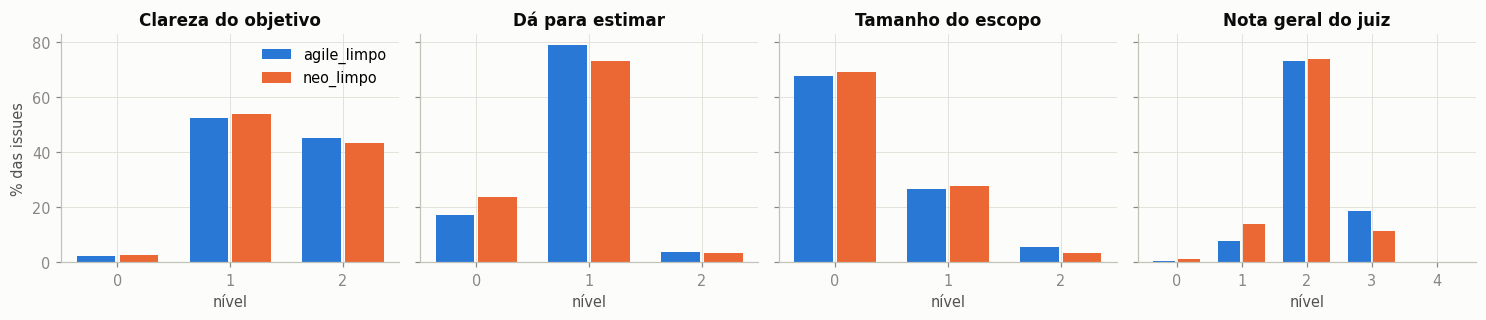

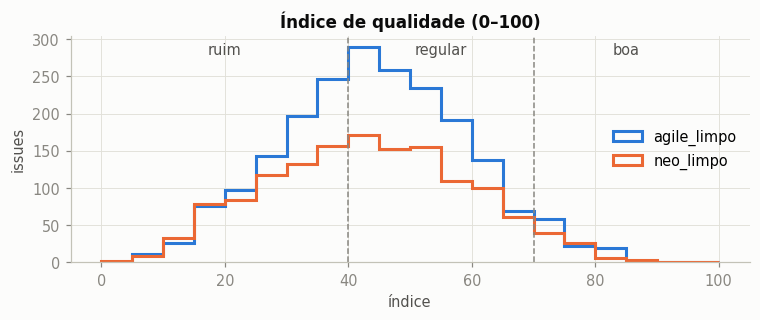

In [6]:
SECAO = "1. Visão geral"
labels = {"goal_clarity": "Clareza do objetivo", "estimability": "Dá para estimar",
          "scope_size": "Tamanho do escopo", "overall_quality": "Nota geral do juiz"}
qs = [q for q in labels if f"{q}_nivel" in J]
fig, axes = plt.subplots(1, len(qs), figsize=(3.4 * len(qs), 3), sharey=True)
for ax, q in zip(np.atleast_1d(axes), qs):
    levels = range(len(QUESTIONS[q]["criteria"]))
    w = 0.38
    for k, ds in enumerate(DATASETS):
        sub = J[J.dataset == ds][f"{q}_nivel"]
        pct = [100 * (sub == lv).mean() for lv in levels]
        ax.bar(np.array(list(levels)) + (k - 0.5) * w, pct, width=w - 0.04, color=DS_COLOR[ds], label=ds)
    ax.set_title(labels[q]); ax.set_xticks(list(levels)); ax.set_xlabel("nível")
np.atleast_1d(axes)[0].set_ylabel("% das issues"); np.atleast_1d(axes)[0].legend()
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(0, 101, 5)
for ds in DATASETS:
    ax.hist(J[J.dataset == ds].indice_qualidade, bins=bins, histtype="step", linewidth=2, color=DS_COLOR[ds], label=ds)
for x in (40, 70):
    ax.axvline(x, color=COR["muted"], linewidth=1, linestyle="--")
ax.set_title("Índice de qualidade (0–100)"); ax.set_xlabel("índice"); ax.set_ylabel("issues"); ax.legend()
ax.text(20, ax.get_ylim()[1] * 0.92, "ruim", color=COR["ink2"], ha="center")
ax.text(55, ax.get_ylim()[1] * 0.92, "regular", color=COR["ink2"], ha="center")
ax.text(85, ax.get_ylim()[1] * 0.92, "boa", color=COR["ink2"], ha="center")
fig.tight_layout(); plt.show()

**Contribuição de cada componente para o índice.** O índice é a média de quatro componentes (0–1).
Esta tabela mostra qual deles puxa a nota para baixo, e é aí que uma reescrita teria mais a ganhar.

In [7]:
SECAO = "1. Visão geral"
comp = pd.DataFrame({
    "clareza (goal_clarity/2)": J.goal_clarity / 2,
    "dá p/ estimar (estimability/2)": J.estimability / 2,
    "critérios de aceitação": J.has_acceptance_criteria,
    "sem ambiguidade (1 − is_ambiguous)": 1 - J.is_ambiguous,
    "dataset": J.dataset}).groupby("dataset").mean().T
display((100 * comp).round(1).rename_axis("componente (0–100)"))

dataset,agile_limpo,neo_limpo
componente (0–100),,
clareza (goal_clarity/2),70.000,69.100
dá p/ estimar (estimability/2),43.700,40.500
critérios de aceitação,23.900,31.900
sem ambiguidade (1 − is_ambiguous),39.700,30.800


## 2. Confiança do Jev

O artigo do Jev propõe **aceitar a resposta quando a confiança é alta e escalar (revisar) quando é baixa**.
Aqui: quanto das respostas ficaria "aceito" para cada limiar. Perguntas com pouca cobertura em limiares altos
são aquelas em que o Jev está hesitante, e merecem mais desconfiança.

conf_mediana  aceitas_≥0.5  aceitas_≥0.7  aceitas_≥0.9
dataset     pergunta                                                               
agile_limpo issue_type              1.000        89.700        74.900        58.000
            goal_clarity            0.600        68.300        36.600         7.500
            estimability            0.700        78.300        53.800         7.100
            scope_size              0.900        80.300        66.500        50.000
            overall_quality         0.800        99.000        69.300        15.400
neo_limpo   issue_type              0.900        86.900        70.800        50.400
            goal_clarity            0.600        65.600        34.400         7.400
            estimability            0.700        78.800        51.800         9.800
            scope_size              0.800        79.700        64.900        44.100
            overall_quality         0.800        98.300        68.500        11.800

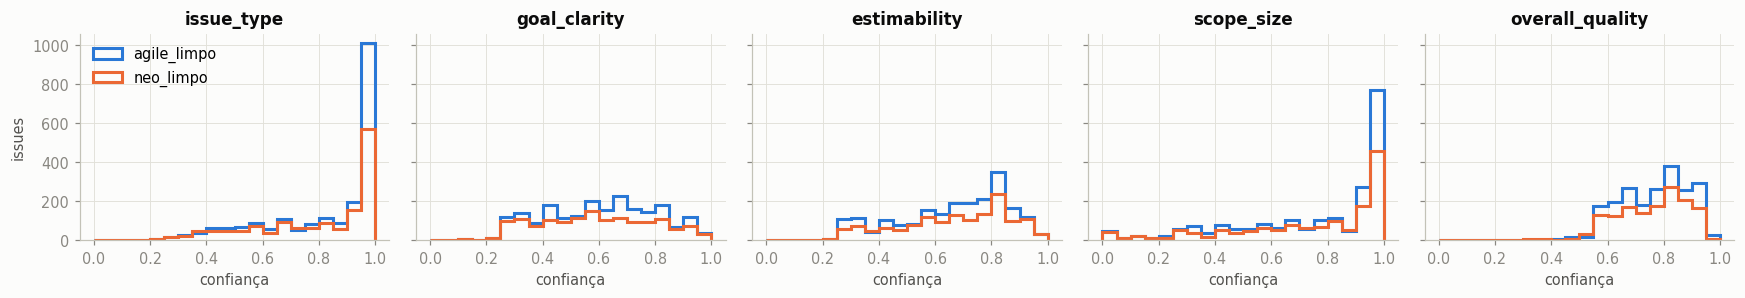

In [8]:
SECAO = "2. Confiança do Jev"
conf_cols = [c for c in J.columns if c.endswith("_conf")]
rows = []
for ds, g in J.groupby("dataset"):
    for c in conf_cols:
        row = {"dataset": ds, "pergunta": c[:-5], "conf_mediana": g[c].median()}
        for t in (0.5, 0.7, 0.9):
            row[f"aceitas_≥{t}"] = 100 * (g[c] >= t).mean()
        rows.append(row)
conf = pd.DataFrame(rows).set_index(["dataset", "pergunta"])
display(conf.round(1))

fig, axes = plt.subplots(1, len(conf_cols), figsize=(3.2 * len(conf_cols), 2.8), sharey=True)
for ax, c in zip(np.atleast_1d(axes), conf_cols):
    for ds in DATASETS:
        ax.hist(J[J.dataset == ds][c].dropna(), bins=np.linspace(0, 1, 21), histtype="step", linewidth=2,
                color=DS_COLOR[ds], label=ds)
    ax.set_title(c[:-5]); ax.set_xlabel("confiança")
np.atleast_1d(axes)[0].set_ylabel("issues"); np.atleast_1d(axes)[0].legend()
fig.tight_layout(); plt.show()

## 3. Qualidade por projeto

Cada projeto é um time com seu jeito de escrever issues. Se a qualidade varia muito entre projetos, comparar
"issues boas × ruins" mistura o efeito da escrita com o efeito do time; por isso a seção 7 controla pelo projeto.

n  indice  pct_ruim  pct_descricao_vazia  sp_mediano
dataset     project                                                                                  
agile_limpo BAM                                 31  36.300    61.300                0.000       1.000
            USERGRID                            33  37.000    54.500                0.000       3.000
            DM                                 399  37.300    55.900                0.000       4.000
            TDQ                                113  41.100    46.000                0.000       5.000
            XD                                 299  41.200    45.500                0.000       3.000
            MULE                                87  43.500    41.400                0.000       5.000
            STUDIO                              73  43.800    41.100                0.000       5.000
            MESOS                              155  45.000    31.600                0.000       3.000
            TESB                                78  45.200    35.900                0.000       2.000
            TIMOB                              209  47.100    30.600                0.000       5.000
            APSTUD                              76  47.200    32.900                0.000       8.000
            DURACLOUD                           62  47.200    21.000                0.000       2.000
            MDL                                117  48.700    29.100                0.000       8.000
            CLOV                                37  48.800    29.700                0.000       2.000
            JSW                                 24  51.000    29.200                0.000       3.000
            TISTUD                             285  53.900    17.900                0.000       5.000
neo_limpo   Minds Backend - Engine (10171263)   89  39.300    55.100                0.000       3.000
            reliability (1304532)              170  39.800    51.200                0.000       2.000
            Minds Mobile (10171280)            192  40.400    52.100                0.000       2.000
            MLReef (12894267)                   27  42.100    40.700                0.000       4.000
            Meltano (7603319)                   22  42.400    40.900                0.000       4.000
            Buyer Experience (28847821)        101  42.400    42.600                0.000       2.000
            opengeoweb (21149814)              166  42.800    41.000                0.000       3.000
            gitlab-ui (7071551)                 31  42.800    41.900                0.000       2.000
            Minds Frontend (10171270)          160  43.100    42.500                0.000       2.000
            customers-gitlab-com (2670515)     153  43.400    39.200                0.000       2.000
            www-gitlab-com (7764)               33  43.600    36.400                0.000       1.000
            Pajamas Design System (4456656)     32  45.900    37.500                0.000       1.500
            triage-ops (7776928)                21  47.400    23.800                0.000       2.000
            Minds (10152778)                    46  51.700    23.900                0.000       3.000
            subway (23285197)                   26  55.900     3.800                0.000       1.500
            nlx (7128869)                       32  60.600    12.500                0.000       3.000

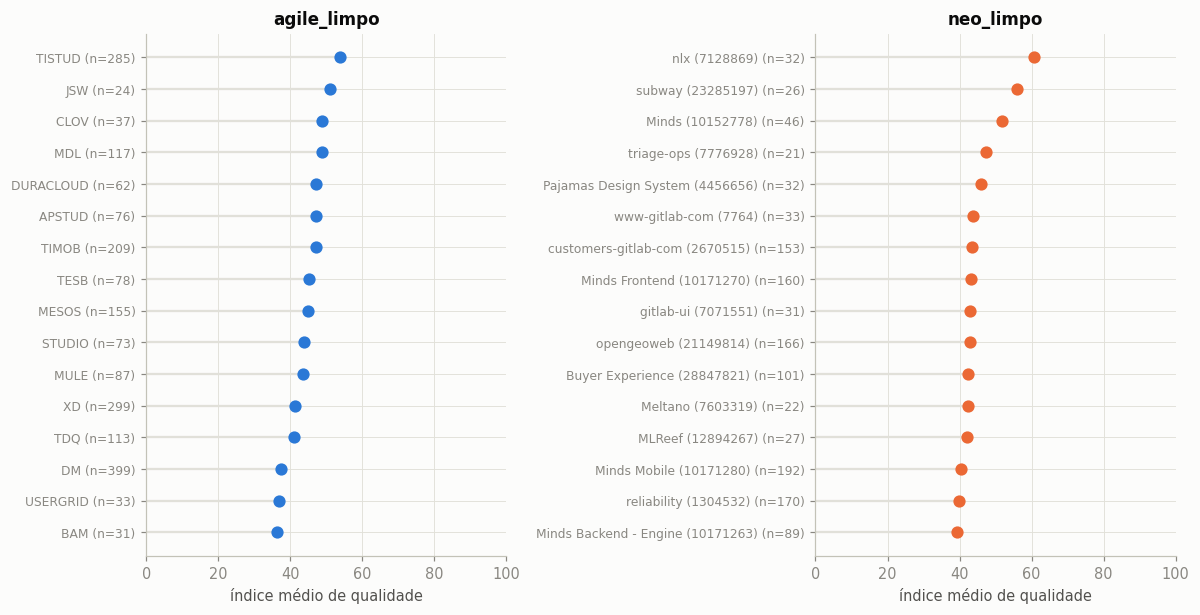

agile_limpo: o projeto explica 13.3% da variação do índice (eta²)
neo_limpo: o projeto explica 7.9% da variação do índice (eta²)


In [9]:
SECAO = "3. Qualidade por projeto"
proj = (J.groupby(["dataset", "project"])
          .agg(n=("issue_id", "size"), indice=("indice_qualidade", "mean"),
               pct_ruim=("faixa", lambda s: 100 * (s == "ruim").mean()),
               pct_descricao_vazia=("empty_description", lambda s: 100 * s.mean()),
               sp_mediano=("sp", "median"))
          .reset_index())
proj = proj[proj.n >= MIN_ISSUES_PROJETO].sort_values(["dataset", "indice"])
proj["project"] = proj.project.map(nome_proj)
display(proj.round(1).set_index(["dataset", "project"]))

fig, axes = plt.subplots(1, len(DATASETS), figsize=(11, 0.28 * proj.groupby("dataset").size().max() + 1.2))
for ax, ds in zip(np.atleast_1d(axes), DATASETS):
    p = proj[proj.dataset == ds]
    ax.hlines(range(len(p)), 0, p.indice, color=COR["grid"], linewidth=1.5)
    ax.plot(p.indice, range(len(p)), "o", color=DS_COLOR[ds], markersize=7)
    ax.set_yticks(range(len(p))); ax.set_yticklabels([f"{a} (n={b})" for a, b in zip(p.project, p.n)], fontsize=8)
    ax.set_xlim(0, 100); ax.set_xlabel("índice médio de qualidade"); ax.set_title(ds)
fig.tight_layout(); plt.show()

# variância explicada pelo projeto (eta²): quanto da qualidade é "do time"
for ds, g in J.groupby("dataset"):
    g = g.dropna(subset=["indice_qualidade"])
    grand = g.indice_qualidade.mean()
    ss_b = g.groupby("project").indice_qualidade.apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum()
    ss_t = ((g.indice_qualidade - grand) ** 2).sum()
    print(f"{ds}: o projeto explica {100 * ss_b / ss_t:.1f}% da variação do índice (eta²)")

## 4. Correlação entre as dimensões (Spearman)

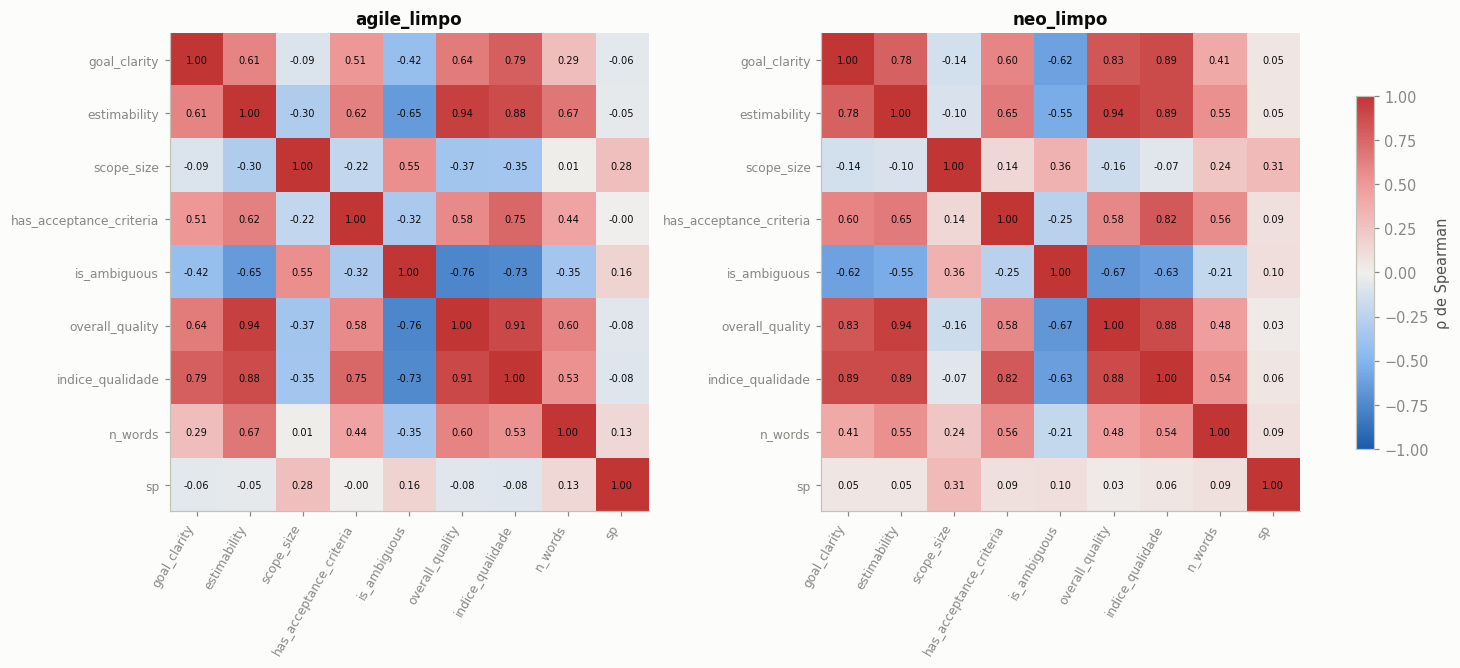

In [10]:
SECAO = "4. Correlação entre as dimensões (Spearman)"
from matplotlib.colors import LinearSegmentedColormap
DIVERGE = LinearSegmentedColormap.from_list("bluered", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a99", "#c23535"])
cols = [c for c in ["goal_clarity", "estimability", "scope_size", "has_acceptance_criteria", "is_ambiguous",
                    "overall_quality", "indice_qualidade", "n_words", "empty_description", "sp"] if c in J]
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.6 * len(DATASETS), 6), constrained_layout=True)
for k, (ax, ds) in enumerate(zip(np.atleast_1d(axes), DATASETS)):
    sub = J[J.dataset == ds][cols]
    sub = sub.loc[:, sub.nunique() > 1]                 # coluna constante não tem correlação
    corr = sub.corr(method="spearman")
    im = ax.imshow(corr, cmap=DIVERGE, vmin=-1, vmax=1)
    names = list(corr.columns)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8); ax.grid(False)
    for a in range(len(names)):
        for b in range(len(names)):
            ax.text(b, a, f"{corr.iloc[a, b]:.2f}", ha="center", va="center", fontsize=6.5, color=COR["ink"])
    ax.set_title(ds)
    registrar(f"correlação {ds}", corr.round(3))
fig.colorbar(im, ax=axes, shrink=0.7, label="ρ de Spearman")
plt.show()

Leitura: correlações **muito altas** entre clareza, estimabilidade e nota geral sugerem que o Jev mede uma
coisa só ("o texto é bom?"), com nomes diferentes. Correlação com `n_words` mostra o quanto o julgamento
é só "texto longo = bom".

## 5. Validação do Jev sem rotulagem humana

Três checagens com gabaritos que já existem nos dados:

**5a. Contra sinais objetivos.** Onde a resposta pode ser verificada por regra simples.

In [11]:
SECAO = "5. Validação do Jev sem rotulagem humana"
from sklearn.metrics import cohen_kappa_score, confusion_matrix

def concordancia(a, b):
    a, b = np.asarray(a).astype(int), np.asarray(b).astype(int)
    return {"n": len(a), "concordância_%": 100 * (a == b).mean(), "kappa": cohen_kappa_score(a, b),
            "%_sim_regra": 100 * a.mean(), "%_sim_jev": 100 * b.mean()}

rows = []
for ds, g in J.groupby("dataset"):
    rows.append({"dataset": ds, "checagem": "critérios de aceitação: regex × Jev",
                 **concordancia(g.acceptance_criteria_text, g.has_acceptance_criteria_sim)})
    rows.append({"dataset": ds, "checagem": "formato 'As a… I want': regex × Jev diz user_story",
                 **concordancia(g.user_story_format, g.issue_type == "user_story")})
display(pd.DataFrame(rows).set_index(["dataset", "checagem"]).round(2))

# descrição vazia deveria derrubar a estimabilidade e a clareza
display(J.groupby(["dataset", "empty_description"])[["goal_clarity", "estimability", "indice_qualidade"]]
          .mean().rename(index={0: "com descrição", 1: "sem descrição"}, level=1).round(2))
print("A regex de critérios de aceitação é estreita (procura 'acceptance criteria', Given/When/Then, checklist).")
print("Se o Jev diz 'sim' muito mais que a regex, ele pode estar contando passos de reprodução como critério.")

n  concordância_%  kappa  %_sim_regra  %_sim_jev
dataset     checagem                                                                                               
agile_limpo critérios de aceitação: regex × Jev                 2078          87.250  0.040        0.380     12.950
            formato 'As a… I want': regex × Jev diz user_story  2078          93.940  0.310        1.730      7.310
neo_limpo   critérios de aceitação: regex × Jev                 1437          78.910  0.440       27.420     22.620
            formato 'As a… I want': regex × Jev diz user_story  1437          91.580  0.330        2.920     10.230

,,goal_clarity,estimability,indice_qualidade
dataset,empty_description,,,
agile_limpo,com descrição,1.400,0.870,44.340
neo_limpo,com descrição,1.380,0.810,43.100


A regex de critérios de aceitação é estreita (procura 'acceptance criteria', Given/When/Then, checklist).
Se o Jev diz 'sim' muito mais que a regex, ele pode estar contando passos de reprodução como critério.


**5b. Contra as labels de tipo do GitLab (só NEO).** ~30% das issues do NEO têm uma label de tipo colocada
pelo próprio time (`type::bug`, `type::feature`, `type::maintenance`…). Elas viram gabarito para a pergunta
`issue_type`. A célula abaixo baixa os JSONs do NEO na versão fixada (≈71 MB, só na primeira vez).

In [12]:
SECAO = "5. Validação do Jev sem rotulagem humana"
import urllib.request
NEO_JSON = config.DATA_RAW / "neo_json"
LABELS_CSV = config.DATA_PROCESSED / "neo_issue_labels.csv"

def tipo_gold(labels):
    L = [l.lower().strip() for l in labels]
    tags = set()
    if any(l in ("type::bug", "bug", "type::regression", "regression") for l in L): tags.add("bug")
    if any(l in ("type::feature", "feature", "feature request", "feature-request", "type::user feature",
                 "feature::addition", "feature::enhancement", "enhancement", "type::enhancement") for l in L): tags.add("feature")
    if any(l in ("type::maintenance", "type::chore", "maintenance::refactor", "backlog::technicaldebt",
                 "technical debt", "tech debt", "refactor", "refactoring", "type::tooling") for l in L): tags.add("maintenance")
    if any(l in ("documentation", "type::documentation", "docs") for l in L): tags.add("documentation")
    return tags.pop() if len(tags) == 1 else ("conflito" if tags else None)

if not LABELS_CSV.exists():
    NEO_JSON.mkdir(parents=True, exist_ok=True)
    rows = []
    for pid in config.NEO_PROJECT_IDS:
        if pid in config.NEO_EXCLUDED_PROJECTS:
            continue
        dest = NEO_JSON / f"{pid}.json"
        if not dest.exists():
            url = f"https://raw.githubusercontent.com/{config.NEO_REPO}/{config.NEO_COMMIT}/util/json/{pid}.json"
            print("baixando", pid); urllib.request.urlretrieve(url, dest)
        for it in json.loads(dest.read_text(encoding="utf-8")):
            labs = it.get("labels") or []
            rows.append({"issue_id": f"{pid}-{it['id']}", "labels": " | ".join(labs), "tipo_gitlab": tipo_gold(labs)})
    pd.DataFrame(rows).to_csv(LABELS_CSV, index=False)
labels_neo = pd.read_csv(LABELS_CSV, dtype={"issue_id": str})
print(labels_neo.tipo_gitlab.value_counts(dropna=False))

tipo_gitlab
NaN              13076
bug               2916
feature           2679
maintenance       1627
documentation      118
conflito            63
Name: count, dtype: int64


In [13]:
SECAO = "5. Validação do Jev sem rotulagem humana"
N = J[J.dataset.map(config.base_dataset) == "neo"].merge(labels_neo, on="issue_id", how="left")
G = N[N.tipo_gitlab.isin(["bug", "feature", "maintenance", "documentation"])].copy()
print(f"{len(G)} das {len(N)} issues do NEO avaliadas pelo Jev têm label de tipo inequívoca")

# mapeamento das categorias do Jev para as do GitLab
JEV2GOLD = {"bug": "bug", "user_story": "feature", "improvement": "feature",
            "technical_task": "maintenance", "other": "documentation"}
G["jev_mapeado"] = G.issue_type.map(JEV2GOLD)
ordem = ["bug", "feature", "maintenance", "documentation"]
cm = pd.crosstab(G.tipo_gitlab, G.jev_mapeado).reindex(index=ordem, columns=ordem, fill_value=0)
display(cm.rename_axis(index="GitLab (gabarito)", columns="Jev"))

bin_ = {"n": len(G), "acurácia bug×não-bug_%": 100 * ((G.tipo_gitlab == "bug") == (G.issue_type == "bug")).mean(),
        "kappa bug×não-bug": cohen_kappa_score(G.tipo_gitlab == "bug", G.issue_type == "bug"),
        "acurácia 4 classes_%": 100 * (G.tipo_gitlab == G.jev_mapeado).mean(),
        "kappa 4 classes": cohen_kappa_score(G.tipo_gitlab, G.jev_mapeado)}
display(pd.Series(bin_).round(3).to_frame("valor"))

# acurácia quando só aceitamos respostas confiantes
rows = []
for t in (0.0, 0.5, 0.7, 0.9):
    s = G[G.issue_type_conf >= t]
    if len(s):
        rows.append({"limiar": t, "cobertura_%": 100 * len(s) / len(G),
                     "acurácia bug×não-bug_%": 100 * ((s.tipo_gitlab == "bug") == (s.issue_type == "bug")).mean()})
display(pd.DataFrame(rows).set_index("limiar").round(1))
print("Ressalva: 'feature' no GitLab inclui funcionalidade nova e melhoria; separar user_story de improvement não é avaliável aqui.")

605 das 1437 issues do NEO avaliadas pelo Jev têm label de tipo inequívoca


Jev,bug,feature,maintenance,documentation
GitLab (gabarito),,,,
bug,240,7,2,1
feature,17,150,35,3
maintenance,17,16,97,5
documentation,0,2,0,13


,valor
n,605.000
acurácia bug×não-bug_%,92.727
kappa bug×não-bug,0.852
acurácia 4 classes_%,82.645
kappa 4 classes,0.739


,cobertura_%,acurácia bug×não-bug_%
limiar,,
0.000,100.000,92.700
0.500,89.400,93.500
0.700,74.700,95.800
0.900,57.200,96.200


Ressalva: 'feature' no GitLab inclui funcionalidade nova e melhoria; separar user_story de improvement não é avaliável aqui.


**5c. `scope_size` × story points.** Se o Jev percebe o tamanho, issues que ele acha maiores deveriam ter mais
pontos. Como cada time usa uma escala, comparamos **dentro de cada projeto** (posto do SP no projeto).

In [14]:
SECAO = "5. Validação do Jev sem rotulagem humana"
J["sp_posto_proj"] = J.groupby(["dataset", "project"]).sp.rank(pct=True)
rows = []
for ds, g in J.groupby("dataset"):
    for q in [c for c in ["scope_size", "estimability", "goal_clarity", "indice_qualidade", "n_words"] if c in g]:
        x = g[[q, "sp_posto_proj"]].dropna()
        rho, p = stats.spearmanr(x[q], x.sp_posto_proj)
        rows.append({"dataset": ds, "variável": q, "ρ com SP (dentro do projeto)": rho, "p": p, "n": len(x)})
display(pd.DataFrame(rows).set_index(["dataset", "variável"]).round(3))
print("scope_size deveria ter ρ positivo. Compare com n_words: se o texto longo já explica o mesmo, o Jev não acrescenta.")

ρ com SP (dentro do projeto)     p     n
dataset     variável                                                  
agile_limpo scope_size                               0.393 0.000  2078
            estimability                            -0.109 0.000  2078
            goal_clarity                            -0.067 0.002  2078
            indice_qualidade                        -0.148 0.000  2078
            n_words                                  0.109 0.000  2078
neo_limpo   scope_size                               0.335 0.000  1437
            estimability                             0.067 0.010  1437
            goal_clarity                             0.058 0.029  1437
            indice_qualidade                         0.077 0.003  1437
            n_words                                  0.165 0.000  1437

scope_size deveria ter ρ positivo. Compare com n_words: se o texto longo já explica o mesmo, o Jev não acrescenta.


## 6. Qualidade × tamanho da issue

n  sp_mediano  sp_medio  palavras_medianas
dataset     faixa                                                 
agile_limpo ruim      796       5.000     8.200             33.000
            regular  1182       3.000     5.000             59.000
            boa       100       5.000     4.800            113.500
neo_limpo   ruim      614       2.000     2.800             35.000
            regular   749       2.000     3.100             86.000
            boa        74       2.000     3.100            136.000

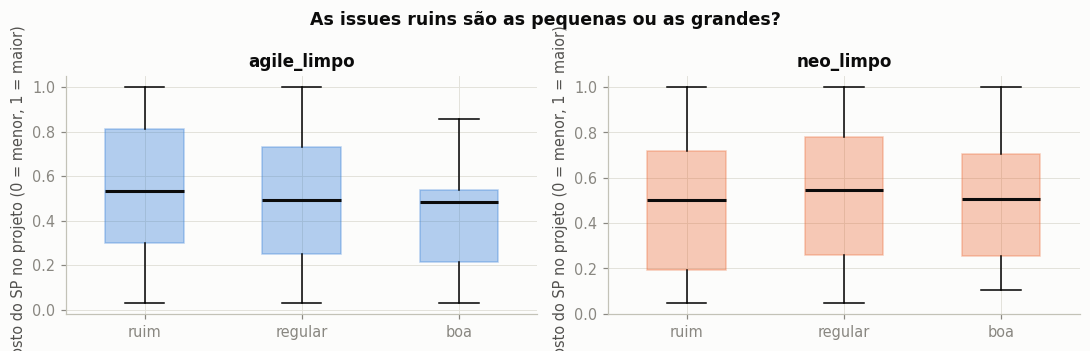

In [15]:
SECAO = "6. Qualidade × tamanho da issue"
tab = (J.groupby(["dataset", "faixa"], observed=True)
         .agg(n=("issue_id", "size"), sp_mediano=("sp", "median"), sp_medio=("sp", "mean"),
              palavras_medianas=("n_words", "median"))
         .round(1))
display(tab)

fig, axes = plt.subplots(1, len(DATASETS), figsize=(10, 3.2), sharey=False)
for ax, ds in zip(np.atleast_1d(axes), DATASETS):
    g = J[J.dataset == ds]
    data = [g[g.faixa == f].sp_posto_proj.dropna() for f in FAIXA_ORDER]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": COR["ink"], "linewidth": 2})
    ax.set_xticks(range(1, len(FAIXA_ORDER) + 1)); ax.set_xticklabels(FAIXA_ORDER)
    for patch in bp["boxes"]:
        patch.set_facecolor(DS_COLOR[ds]); patch.set_alpha(0.35); patch.set_edgecolor(DS_COLOR[ds])
    ax.set_title(ds); ax.set_ylabel("posto do SP no projeto (0 = menor, 1 = maior)")
fig.suptitle("As issues ruins são as pequenas ou as grandes?", fontweight="bold", color=COR["ink"])
fig.tight_layout(); plt.show()

## 7. Qualidade × erro dos modelos

A comparação ingênua ("MAE nas issues ruins × boas") engana, porque as faixas têm tamanhos de issue diferentes
(veja a seção 6) e projetos diferentes. Então:
- **7a.** MAE por faixa (descritivo, com SP médio ao lado)
- **7b.** Regressão do erro absoluto: `|erro| ~ índice + log(1+SP) + projeto`. O coeficiente do índice responde:
  *mantidos o tamanho e o time, issues mais bem escritas são estimadas com menos erro?*

In [16]:
SECAO = "7. Qualidade × erro dos modelos"
import statsmodels.formula.api as smf
preds = []
for ds in DATASETS:
    pdir = config.PREDICTIONS / ds / "within"
    for f in sorted(pdir.glob("*.csv")) if pdir.exists() else []:
        if "_repoonly" in f.stem or "+repo" in f.stem:
            continue
        p = pd.read_csv(f, dtype={"issue_id": str})[["issue_id", "y_true", "y_pred"]]
        p["modelo"], p["dataset"] = f.stem, ds
        preds.append(p)
if not preds:
    print(f"Nenhuma predição em results/predictions/{{{','.join(DATASETS)}}}/within/ — rode 12_run_baselines.py e "
          f"10_run_ml.py --dataset {' '.join(DATASETS)}.")
else:
    P = pd.concat(preds).merge(J[["issue_id", "dataset", "project", "faixa", "indice_qualidade", "issue_type"]],
                               on=["issue_id", "dataset"], how="inner")
    P["abs_err"] = (P.y_true - P.y_pred).abs()
    P["log_sp"] = np.log1p(P.y_true)
    principais = [m for m in ["ProjectMedian", "Median", "SVR", "XGBoost", "RandomForest", "KNN"] if m in set(P.modelo)]
    principais += sorted(m for m in set(P.modelo) if "__" in m)          # LLMs, se houver
    if not principais:
        principais = sorted(set(P.modelo))
    t = (P[P.modelo.isin(principais)]
           .pivot_table(index=["dataset", "faixa"], columns="modelo", values="abs_err", aggfunc="mean", observed=True)
           [principais])
    t.insert(0, "SP_medio", P.groupby(["dataset", "faixa"], observed=True).y_true.mean())
    t.insert(0, "n", P[P.modelo == principais[0]].groupby(["dataset", "faixa"], observed=True).size())
    print("7a. MAE por faixa de qualidade")
    display(t.round(2))

7a. MAE por faixa de qualidade


modelo                  n  SP_medio  ProjectMedian  Median  XGBoost   KNN
dataset     faixa                                                        
agile_limpo ruim      796     8.170          5.590   5.970    5.390 5.870
            regular  1182     5.000          2.680   3.090    3.240 3.570
            boa       100     4.750          1.610   2.010    2.380 2.350
neo_limpo   ruim      614     2.820          1.440   1.460    1.630 1.640
            regular   749     3.080          1.560   1.640    1.620 1.860
            boa        74     3.150          1.590   1.720    1.510 1.640

In [17]:
SECAO = "7. Qualidade × erro dos modelos"
if preds:
    rows = []
    for (ds, m), g in P[P.modelo.isin(principais)].groupby(["dataset", "modelo"]):
        g = g.dropna(subset=["indice_qualidade"])
        fit = smf.ols("abs_err ~ indice_qualidade + log_sp + C(project)", data=g).fit(cov_type="HC3")
        b, ci = fit.params["indice_qualidade"], fit.conf_int().loc["indice_qualidade"]
        rows.append({"dataset": ds, "modelo": m, "Δ|erro| por +10 pts de qualidade": 10 * b,
                     "IC95% inf": 10 * ci[0], "IC95% sup": 10 * ci[1], "p": fit.pvalues["indice_qualidade"],
                     "n": int(fit.nobs)})
    reg = pd.DataFrame(rows).set_index(["dataset", "modelo"])
    print("7b. Efeito da qualidade no erro, controlando tamanho (log SP) e projeto")
    display(reg.round(3))
    print("Negativo e significativo = issues mais bem escritas são estimadas com menos erro.")
    print("ProjectMedian não lê o texto: se ele também 'melhora' com a qualidade, o efeito não vem da leitura do texto.")

7b. Efeito da qualidade no erro, controlando tamanho (log SP) e projeto


Δ|erro| por +10 pts de qualidade  IC95% inf  IC95% sup     p     n
dataset     modelo                                                                           
agile_limpo KNN                                      -0.323     -0.512     -0.133 0.001  2078
            Median                                   -0.240     -0.416     -0.064 0.008  2078
            ProjectMedian                            -0.262     -0.442     -0.082 0.004  2078
            XGBoost                                  -0.168     -0.344      0.007 0.059  2078
neo_limpo   KNN                                      -0.032     -0.120      0.056 0.472  1437
            Median                                   -0.026     -0.094      0.041 0.448  1437
            ProjectMedian                            -0.030     -0.098      0.039 0.397  1437
            XGBoost                                  -0.066     -0.172      0.039 0.218  1437

Negativo e significativo = issues mais bem escritas são estimadas com menos erro.
ProjectMedian não lê o texto: se ele também 'melhora' com a qualidade, o efeito não vem da leitura do texto.


---
# Parte B — Melhorar as issues melhora a estimativa?

**Desenho:**
- Amostra das issues de avaliação de pior qualidade (seção 8).
- Cada uma é reescrita duas vezes, sem que o LLM veja os story points:
  - **melhorar:** o "QA Agent" de Lotfi & Nafil, adaptado. Esclarece, estrutura e só adiciona critérios de aceitação quando dá para deduzi-los do original. Não inventa nada e não fala de tamanho ou esforço.
  - **parafrasear (controle):** reescreve com outras palavras, **sem acrescentar nem tirar informação**. Se "melhorar" ganhar de "parafrasear", o ganho vem de informação ou estrutura, e não de o texto ter sido mexido por um LLM.
- O Jev julga as três versões (original, melhorada, parafraseada).
- Os modelos **treinados no texto original** estimam as três versões, e a mediana do projeto (que não lê o texto) serve de referência fixa.
- O teste é pareado (Wilcoxon), sempre na mesma issue.

> **Limite conceitual importante:** os story points foram dados pelo time lendo o texto *original*. Reescrever não
> muda o rótulo. Um erro menor significa que o texto reescrito "sinaliza" melhor o tamanho que o time atribuiu, não que a
> estimativa ficou "mais verdadeira".

## 8. Seleção das issues

In [18]:
SECAO = "8. Seleção das issues"
pool = J[J.within == "test"].copy()          # todas as issues julgadas do test set
pool["prioridade"] = (pool.faixa == "ruim").astype(int) * 2 + (pool.estimability_nivel == 0).astype(int)
pool["palavras_descricao"] = pool.description.fillna("").map(clean_light).str.split().str.len()
ruins = pool[pool.prioridade > 0]
sem_texto = ruins[ruins.palavras_descricao < MIN_PALAVRAS_DESCRICAO]
display(pd.DataFrame({
    "issues ruins ou não-estimáveis": ruins.groupby("dataset").size(),
    f"com descrição < {MIN_PALAVRAS_DESCRICAO} palavras": sem_texto.groupby("dataset").size(),
    "% sem texto suficiente": (100 * sem_texto.groupby("dataset").size() / ruins.groupby("dataset").size()).round(1),
}).fillna(0), nome="issues ruins sem texto")
print("As issues sem texto ficam FORA do experimento: não há o que reescrever sem inventar.")
print("Esse percentual é um achado em si: boa parte das piores issues não tem informação a melhorar.")
pool = pool[pool.palavras_descricao >= MIN_PALAVRAS_DESCRICAO]
sel = []
for ds, g in pool.groupby("dataset"):
    g = g.sort_values(["prioridade", "indice_qualidade"], ascending=[False, True])
    cand = g[g.prioridade > 0].sample(frac=1, random_state=config.SEED)      # embaralha com seed fixa
    cand = cand.sort_values(["prioridade", "indice_qualidade"], ascending=[False, True], kind="stable")
    # limita issues por projeto para a amostra não ficar concentrada em um time só
    por_projeto = max(3, N_MELHORAR // max(1, cand.project.nunique()) + 1)
    take = cand.groupby("project", group_keys=False).head(por_projeto)
    sel.append(take.head(N_MELHORAR))
SEL = pd.concat(sel)
SEL[["issue_id", "dataset", "project", "sp", "faixa", "indice_qualidade"]].to_csv(EXP / "selecionadas.csv", index=False)
display(SEL.groupby("dataset").agg(n=("issue_id", "size"), projetos=("project", "nunique"),
                                   indice_medio=("indice_qualidade", "mean"), sp_medio=("sp", "mean")).round(1))
print("Candidatas por dataset:", pool[pool.prioridade > 0].groupby("dataset").size().to_dict())

,issues ruins ou não-estimáveis,com descrição < 15 palavras,% sem texto suficiente
dataset,,,
agile_limpo,806,236,29.300
neo_limpo,624,153,24.500


As issues sem texto ficam FORA do experimento: não há o que reescrever sem inventar.
Esse percentual é um achado em si: boa parte das piores issues não tem informação a melhorar.


,n,projetos,indice_medio,sp_medio
dataset,,,,
agile_limpo,100,16,23.800,8.000
neo_limpo,96,26,24.900,3.700


Candidatas por dataset: {'agile_limpo': 570, 'neo_limpo': 471}


## 9. Reescrita com LLM

As respostas ficam em `results/improvement/rewrites_{condição}.jsonl`. Se parar, rode a célula de novo e ela continua.

In [19]:
SECAO = "9. Reescrita com LLM"
from see.llm_clients import LLMClient, call_with_retry
from see.prompts import truncate

PROMPT_MELHORAR = '''You are a Quality Analyst on an agile team. Rewrite the work item below to improve clarity, structure and testability, following the INVEST and Quality User Story criteria.

Rules:
- Preserve the original intent, scope and every technical detail. Do NOT invent features, requirements, numbers or context that are not in the original.
- Use the format "As a <role>, I want <goal>, so that <benefit>" only if the role and benefit can be inferred from the original; for bugs and technical tasks keep a clear problem statement instead.
- Add acceptance criteria ONLY if they can be inferred from the original text.
- Remove ambiguity and vague wording; prefer active voice.
- Never mention effort, size, complexity, time or story points.
- If the original contains little information, keep the rewrite short. Do not fill gaps with assumptions.

Original work item:
Title: {title}
Description: {description}

Respond ONLY with a JSON object with three string fields: "title" (the rewritten title), "description" (the rewritten description) and "justification" (one sentence explaining the changes).'''

PROMPT_PARAFRASEAR = '''Paraphrase the work item below using different words and sentence structure.

Rules:
- Keep exactly the same information: do NOT add, remove, clarify or restructure content. Do not add acceptance criteria, user-story format or headings that are not in the original.
- Keep roughly the same length. Paraphrase BOTH the title and the description.
- Never mention effort, size, complexity, time or story points.

Original work item:
Title: {title}
Description: {description}

Respond ONLY with a JSON object with three string fields: "title" (the paraphrased title), "description" (the paraphrased description) and "justification" (one sentence).'''

PROMPTS = {"melhorar": PROMPT_MELHORAR, "parafrasear": PROMPT_PARAFRASEAR}
FORBIDDEN = re.compile(r"story ?points?|\bpoints?\b|\bhours?\b|\bdays?\b|effort|estimat", re.I)

import hashlib
PLACEHOLDER = re.compile(r"^\s*(\.{2,}|…|<[^>]*>|n/?a|none|null|tbd)?\s*$", re.I)

def valida(d, original_desc):
    # rejeita respostas vazias, placeholders ('...') e descrições apagadas
    if not d:
        return False
    if PLACEHOLDER.match(d["title"]):                       # título vazio ou "..."
        return False
    if original_desc.strip() and PLACEHOLDER.match(d["description"]):   # descrição apagada ou "..."
        return False
    return True

def parse_json(text):
    text = re.sub(r"<think>.*?</think>", " ", text or "", flags=re.S)
    m = re.search(r"\{.*\}", text, flags=re.S)
    if not m:
        return None
    try:
        d = json.loads(m.group(0))
        return d if isinstance(d.get("title"), str) and isinstance(d.get("description"), str) else None
    except json.JSONDecodeError:
        return None

def done_ids(path):
    if not path.exists():
        return {}
    out = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line)
            if r.get("ok"):
                out[r["issue_id"]] = r
    return out

def rewrite_all(cond, rows, client, rpm=0):
    versao = hashlib.sha1((PROMPTS[cond] + client.model).encode()).hexdigest()[:8]
    path = EXP / f"rewrites_{cond}_{re.sub(r'[^A-Za-z0-9._-]', '-', client.model)}_{versao}.jsonl"
    done = done_ids(path)
    todo = [r for r in rows.itertuples() if r.issue_id not in done]
    print(f"{cond}: {len(done)} prontas, {len(todo)} a fazer")
    last = 0.0
    with open(path, "a", encoding="utf-8") as f:
        for n, r in enumerate(todo, 1):
            if rpm:
                time.sleep(max(0, 60 / rpm - (time.time() - last)))
            last = time.time()
            orig_desc = truncate(clean_light(r.description), 3000)
            prompt = PROMPTS[cond].format(title=clean_light(r.title), description=orig_desc or "(no description)")
            rec = {"issue_id": r.issue_id, "condicao": cond, "model": client.model}
            try:
                text, lat, _ = call_with_retry(client, prompt)
                d = parse_json(text)
                rec.update(ok=valida(d, orig_desc), raw=text[:4000], latency_s=round(lat, 2), **(d or {}))
            except Exception as e:
                rec.update(ok=False, error=str(e)[:300])
            f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
            if n % 10 == 0 or n == len(todo):
                print(f"   {n}/{len(todo)}")
    return done_ids(path)

_KEYS = {"gemini": "GEMINI_API_KEY", "groq": "GROQ_API_KEY", "openrouter": "OPENROUTER_API_KEY"}
if REWRITER["provider"] in _KEYS:
    pedir_chave(_KEYS[REWRITER["provider"]], "quem reescreve")
rewriter = LLMClient(REWRITER["provider"], REWRITER["model"], temperature=0.0, max_tokens=1500, seed=config.SEED)
REW = {c: rewrite_all(c, SEL, rewriter, REWRITER_RPM) for c in PROMPTS}

melhorar: 189 prontas, 7 a fazer
   7/7
parafrasear: 191 prontas, 5 a fazer
   5/5


In [20]:
SECAO = "9. Reescrita com LLM"
# ---- checagens das reescritas ----
ok_ids = set(SEL.issue_id) & set(REW["melhorar"]) & set(REW["parafrasear"])
print(f"{len(ok_ids)}/{len(SEL)} issues com as duas reescritas válidas (só elas entram nas comparações pareadas)")

def versoes():
    base = SEL[SEL.issue_id.isin(ok_ids)][["issue_id", "dataset", "project", "sp", "title", "description"]]
    out = {"original": base.assign(title=base.title.map(clean_light), description=base.description.map(clean_light))}
    for c in PROMPTS:
        v = base.copy()
        v["title"] = v.issue_id.map(lambda i: REW[c][i]["title"])
        v["description"] = v.issue_id.map(lambda i: REW[c][i]["description"])
        out[c] = v
    return out
V = versoes()

chk = []
for name, v in V.items():
    words = (v.title + " " + v.description).str.split().str.len()
    chk.append({"versão": name, "palavras (mediana)": words.median(),
                "menciona esforço/tempo/pontos_%": 100 * (v.title + " " + v.description).str.contains(FORBIDDEN).mean(),
                "formato 'As a… I want'_%": 100 * v.description.str.contains(rep.US_FORMAT).mean(),
                "critérios de aceitação (regex)_%": 100 * v.description.str.contains(rep.ACCEPTANCE).mean()})
STOP = set(("a an the and or of to in on for with by from at as is are was were be been it this that these those "
             "not no but if then than so such can could should would will may might must do does did done has have "
             "had i we you they he she its our your their my me us them which who what when where how all any each "
             "some more most other into also only just there here up out over about after before while because").split())
def palavras(t):
    return {w for w in re.findall(r"[a-z][a-z0-9_]{2,}", (t or "").lower()) if w not in STOP}
orig_words = {r.issue_id: palavras(r.title + " " + r.description) for r in V["original"].itertuples()}
for name, v in V.items():
    nov = [len(palavras(t + " " + d) - orig_words[i]) / max(1, len(palavras(t + " " + d)))
           for i, t, d in zip(v.issue_id, v.title, v.description)]
    v["novidade_%"] = 100 * np.array(nov)
    chk[[c["versão"] for c in chk].index(name)]["palavras novas (mediana %)"] = np.median(v["novidade_%"])
display(pd.DataFrame(chk).set_index("versão").round(1), nome="checagens das reescritas")
print("Se 'menciona esforço' subir nas reescritas, o LLM pode estar vazando pistas de tamanho; revise essas issues.")
print("'Palavras novas' = % das palavras do texto reescrito que não existem no original. No 'parafrasear' é")
print("esperado (sinônimos); no 'melhorar', valores muito altos indicam conteúdo inventado.")

LADO = V["original"][["issue_id", "dataset", "sp", "title", "description"]].rename(
    columns={"title": "titulo_original", "description": "descricao_original"})
for c in PROMPTS:
    LADO = LADO.merge(V[c][["issue_id", "title", "description", "novidade_%"]].rename(
        columns={"title": f"titulo_{c}", "description": f"descricao_{c}", "novidade_%": f"novidade_{c}_%"}), on="issue_id")
registrar("reescritas lado a lado", LADO)
print("\nAs 5 'melhoradas' com mais palavras novas (leia: são as mais suspeitas de invenção):")
_ipy_display(LADO.sort_values("novidade_melhorar_%", ascending=False).head(5)
             [["issue_id", "titulo_original", "descricao_original", "descricao_melhorar", "novidade_melhorar_%"]])

i0 = sorted(ok_ids)[0]
for name, v in V.items():
    r = v[v.issue_id == i0].iloc[0]
    print(f"\n===== {name.upper()} ({i0}) =====\nTITLE: {r.title}\n{r.description[:1200]}")

189/196 issues com as duas reescritas válidas (só elas entram nas comparações pareadas)


,palavras (mediana),menciona esforço/tempo/pontos_%,formato 'As a… I want'_%,critérios de aceitação (regex)_%,palavras novas (mediana %)
versão,,,,,
original,38.000,3.700,3.700,12.700,0.000
melhorar,34.000,2.600,20.600,0.000,41.700
parafrasear,35.000,2.100,2.600,3.700,54.500


Se 'menciona esforço' subir nas reescritas, o LLM pode estar vazando pistas de tamanho; revise essas issues.
'Palavras novas' = % das palavras do texto reescrito que não existem no original. No 'parafrasear' é
esperado (sinônimos); no 'melhorar', valores muito altos indicam conteúdo inventado.

As 5 'melhoradas' com mais palavras novas (leia: são as mais suspeitas de invenção):


,issue_id,titulo_original,descricao_original,descricao_melhorar,novidade_melhorar_%
96,10171270-20299452,(chore): resolve,Is this a bug? Make sure to use the Bug templa...,"When a JSON response is received, ensure that ...",94.118
98,10152778-17407589,Documentation on &26 and &30,Is this a bug? Make sure to use the Bug templa...,The documentation for &26 and &30 is incomplet...,88.889
35,TDQ-00525,oracle can not get tables,"create an oracle dbconnection, can not get tab...","As a developer, I want to establish a reliable...",87.500
95,10171270-21182467,(chore): Follow and changes to analytics,Is this a bug? Make sure to use the Bug templa...,"Currently, analytics changes are not being mon...",86.364
105,10171270-19263182,(feat): Attempt to sync more activities,Is this a bug? Make sure to use the Bug templa...,"When attempting to sync multiple activities, t...",85.714



===== ORIGINAL (10152778-124642508) =====
TITLE: Vitess issues
Is minds.com down? Vitess is What is the issue? Issues with Vitess What username are you logged in with? Any user Console logs N/A

===== MELHORAR (10152778-124642508) =====
TITLE: Vitess Issues
As a user, I want to know the status of minds.com and the issue with Vitess, so that I can troubleshoot or seek assistance. Provide the username I'm logged in with and any available console logs.

===== PARAFRASEAR (10152778-124642508) =====
TITLE: Vitess Troubleshooting
Is minds.com experiencing downtime? What is the root cause of the issue? Are there problems with Vitess? What is the current username and login status? Are there any relevant console logs available?


## 10. Reavaliação com o Jev (antes × depois)

O Jev julga as versões reescritas com as mesmas perguntas. A original já foi julgada: reaproveitamos esse resultado.
⚠ *Goodhart:* a reescrita foi orientada pelos mesmos critérios que o Jev mede. Melhora no Jev é esperada e
**não basta**; o teste que importa é a seção 11.

In [29]:
SECAO = "10. Reavaliação com o Jev (antes × depois)"
judge_mod = load_script("50_quality_judge.py")
if ENGINE == "jev":
    pedir_chave("TYPESAFE_API_KEY", "Jev")
judge = judge_mod.Judge(ENGINE, None, None)

def judge_version(name, v):
    path = EXP / f"jev_{name}.jsonl"
    done = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line)
                if not r.get("error"):
                    done[r["issue_id"]] = r
    todo = v[~v.issue_id.isin(done)]
    print(f"Jev / {name}: {len(done)} prontas, {len(todo)} a fazer")
    with open(path, "a", encoding="utf-8") as f:
        for r in todo.itertuples():
            state = f"Title: {r.title}\nDescription: {truncate(r.description, 2000) or '(no description)'}"
            rec = {"issue_id": r.issue_id}
            try:
                resp, lat = judge.ask(state, QUESTIONS)
                rec.update(answers=resp.get("answers", {}), error=None)
            except Exception as e:
                rec.update(answers={}, error=str(e)[:300])
            f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
            if rec["error"]:
                done[r.issue_id] = None
            else:
                done[r.issue_id] = rec
    rows = [{"issue_id": i, **judge_mod.flatten(rec["answers"], QUESTIONS)} for i, rec in done.items() if rec]
    return add_quality_scores(pd.DataFrame(rows))

JV = {"original": add_quality_scores(J[J.issue_id.isin(ok_ids)][["issue_id"] + [c for c in J.columns
        if c.split("_conf")[0] in QUESTIONS or c.startswith("issue_type")]].copy())}
for c in PROMPTS:
    JV[c] = judge_version(c, V[c])

Jev / melhorar: 0 prontas, 189 a fazer
Jev / parafrasear: 0 prontas, 189 a fazer


antes  depois   n  Δ média  p (Wilcoxon)  r (rank-biserial)
condição    dataset     dimensão                                                                            
melhorar    agile_limpo indice_qualidade        23.735  29.518  93    5.783         0.000              0.743
                        nota_geral_juiz         40.792  45.531  93    4.739         0.000              0.723
                        goal_clarity             0.898   1.107  93    0.208         0.000              0.797
                        estimability             0.399   0.503  93    0.104         0.000              0.448
                        has_acceptance_criteria  0.092   0.112  93    0.020         0.000              0.552
                        is_ambiguous             0.792   0.737  93   -0.055         0.000             -0.533
                        scope_size               0.557   0.453  93   -0.104         0.002             -0.375
            neo_limpo   indice_qualidade        24.918  32.319  96    7.401         0.000              0.795
                        nota_geral_juiz         36.555  46.096  96    9.541         0.000              0.892
                        goal_clarity             0.913   1.185  96    0.272         0.000              0.835
                        estimability             0.389   0.532  96    0.143         0.000              0.636
                        has_acceptance_criteria  0.151   0.167  96    0.016         0.014              0.299
                        is_ambiguous             0.805   0.733  96   -0.072         0.000             -0.690
                        scope_size               0.597   0.422  96   -0.175         0.000             -0.587
parafrasear agile_limpo indice_qualidade        23.735  23.929  93    0.194         0.972             -0.005
                        nota_geral_juiz         40.792  42.142  93    1.349         0.239              0.140
                        goal_clarity             0.898   0.936  93    0.038         0.224              0.145
                        estimability             0.399   0.363  93   -0.035         0.036             -0.250
                        has_acceptance_criteria  0.092   0.098  93    0.006         0.019              0.294
                        is_ambiguous             0.792   0.791  93   -0.001         0.396             -0.103
                        scope_size               0.557   0.576  93    0.019         0.277              0.120
            neo_limpo   indice_qualidade        24.918  26.681  96    1.764         0.088              0.200
                        nota_geral_juiz         36.555  39.036  96    2.481         0.029              0.253
                        goal_clarity             0.913   0.988  96    0.075         0.039              0.242
                        estimability             0.389   0.379  96   -0.009         0.512             -0.076
                        has_acceptance_criteria  0.151   0.181  96    0.030         0.121              0.186
                        is_ambiguous             0.805   0.797  96   -0.008         0.407             -0.102
                        scope_size               0.597   0.611  96    0.014         0.513              0.076

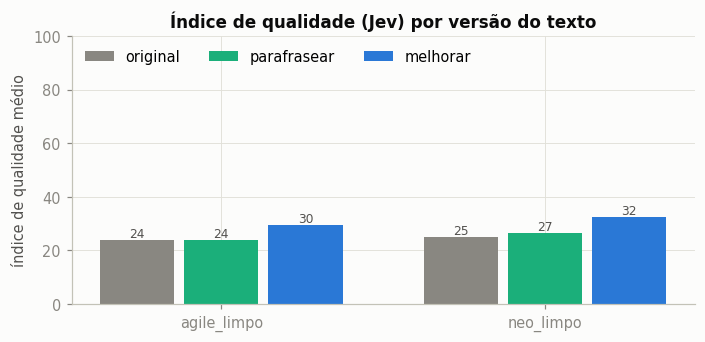

In [30]:
SECAO = "10. Reavaliação com o Jev (antes × depois)"
def wilcoxon_pareado(a, b):
    d = (b - a).dropna()
    if len(d) < 5 or (d == 0).all():
        return {"n": len(d), "Δ média": d.mean(), "p (Wilcoxon)": np.nan, "r (rank-biserial)": np.nan}
    w = stats.wilcoxon(d)
    ranks = d.abs().rank()
    r_rb = (ranks[d > 0].sum() - ranks[d < 0].sum()) / ranks.sum()
    return {"n": len(d), "Δ média": d.mean(), "p (Wilcoxon)": w.pvalue, "r (rank-biserial)": r_rb}

dims = [c for c in ["indice_qualidade", "nota_geral_juiz", "goal_clarity", "estimability", "has_acceptance_criteria",
                    "is_ambiguous", "scope_size"] if c in JV["original"]]
rows = []
meta = SEL.set_index("issue_id").dataset
for c in PROMPTS:
    m = JV["original"].set_index("issue_id")[dims].join(JV[c].set_index("issue_id")[dims], rsuffix="_novo", how="inner")
    for ds in DATASETS:
        mm = m[m.index.map(meta) == ds]
        for d in dims:
            rows.append({"condição": c, "dataset": ds, "dimensão": d, "antes": mm[d].mean(), "depois": mm[f"{d}_novo"].mean(),
                         **wilcoxon_pareado(mm[d], mm[f"{d}_novo"])})
JEVDIFF = pd.DataFrame(rows).set_index(["condição", "dataset", "dimensão"])
display(JEVDIFF.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(len(DATASETS)); w = 0.26
for k, (nome, cor) in enumerate([("original", COR["muted"]), ("parafrasear", COR["s3"]), ("melhorar", COR["s1"])]):
    vals = [JV[nome][JV[nome].issue_id.map(meta) == ds].indice_qualidade.mean() for ds in DATASETS]
    ax.bar(x + (k - 1) * w, vals, width=w - 0.03, color=cor, label=nome)
    for xi, v in zip(x + (k - 1) * w, vals):
        ax.text(xi, v + 1, f"{v:.0f}", ha="center", color=COR["ink2"], fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(DATASETS); ax.set_ylim(0, 100); ax.set_ylabel("índice de qualidade médio")
ax.set_title("Índice de qualidade (Jev) por versão do texto"); ax.legend(ncol=3, loc="upper left")
fig.tight_layout(); plt.show()

## 11. Reestimativa (antes × depois)

- **ML:** cada modelo é treinado uma vez no **texto original** do treino (within) e estima as três versões das
  issues selecionadas. É o cenário realista: o modelo já existe e você melhora só a issue nova.
- **LLM zero-shot (opcional):** o mesmo prompt ZS1 do artigo para as três versões.
- **ProjectMedian:** não lê o texto, então tem o mesmo erro nas três versões e serve de linha de referência.

In [31]:
SECAO = "11. Reestimativa (antes × depois)"
ml = load_script("10_run_ml.py")
EST = []
for ds in DATASETS:
    df = load_merged(ds)
    tr = df[df.within == "train"]
    ids = V["original"][V["original"].dataset == ds].issue_id
    if not len(ids):
        continue
    for mname in ESTIMADORES_ML:
        cache = EXP / f"pred_{ds}_{mname}.csv"
        if cache.exists():
            EST.append(pd.read_csv(cache, dtype={"issue_id": str})); continue
        print(f"treinando {mname} ({ds}) no texto original...")
        texts = {n: V[n].set_index("issue_id").loc[ids].pipe(lambda v: (v.title + ". " + v.description).str.lower())
                 for n in V}
        allx = pd.concat(list(texts.values()))
        x_tr, x_pr = ml.featurize(tr.text_full, allx, 0)
        model = ml.make_model(mname); model.fit(x_tr, tr.sp.to_numpy())
        yhat = model.predict(x_pr)
        out, k = [], 0
        for n, t in texts.items():
            out.append(pd.DataFrame({"issue_id": t.index, "versao": n, "modelo": mname, "dataset": ds,
                                     "y_pred": yhat[k:k + len(t)]})); k += len(t)
        out = pd.concat(out); out.to_csv(cache, index=False); EST.append(out)
    # referência que não lê o texto
    med = tr.groupby("project").sp.median()
    base = V["original"][V["original"].dataset == ds]
    for n in V:
        EST.append(pd.DataFrame({"issue_id": base.issue_id, "versao": n, "modelo": "ProjectMedian", "dataset": ds,
                                 "y_pred": base.project.map(med).values}))
EST = pd.concat(EST, ignore_index=True)

treinando KNN (agile_limpo) no texto original...
treinando XGBoost (agile_limpo) no texto original...
treinando KNN (neo_limpo) no texto original...
treinando XGBoost (neo_limpo) no texto original...


KeyboardInterrupt: 

In [ ]:
SECAO = "11. Reestimativa (antes × depois)"
from see.prompts import zero_shot, parse_estimate
if ESTIMADOR_LLM:
    if ESTIMADOR_LLM["provider"] in _KEYS:
        pedir_chave(_KEYS[ESTIMADOR_LLM["provider"]], "LLM estimador")
    est_client = LLMClient(ESTIMADOR_LLM["provider"], ESTIMADOR_LLM["model"], temperature=0.0, seed=config.SEED)
    tag = f"LLM:{ESTIMADOR_LLM['model']}"
    for n, v in V.items():
        path = EXP / f"llm_{re.sub(r'[^A-Za-z0-9._-]', '-', ESTIMADOR_LLM['model'])}_{n}.jsonl"
        done = {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                if line.strip():
                    r = json.loads(line); done[r["issue_id"]] = r
        todo = v[~v.issue_id.isin(done)]
        print(f"{tag} / {n}: {len(done)} prontas, {len(todo)} a fazer")
        with open(path, "a", encoding="utf-8") as f:
            for r in todo.itertuples():
                try:
                    text, _, _ = call_with_retry(est_client, zero_shot("ZS1", r.title, truncate(r.description, 2000)))
                    rec = {"issue_id": r.issue_id, "y_pred": parse_estimate(text), "raw": text[:200]}
                except Exception as e:
                    rec = {"issue_id": r.issue_id, "y_pred": None, "error": str(e)[:200]}
                f.write(json.dumps(rec) + "\n"); f.flush(); done[r.issue_id] = rec
        EST = pd.concat([EST, pd.DataFrame({"issue_id": list(done), "versao": n, "modelo": tag,
                                            "dataset": v.set_index("issue_id").loc[list(done)].dataset.values,
                                            "y_pred": [done[i]["y_pred"] for i in done]})], ignore_index=True)
else:
    print("ESTIMADOR_LLM = None → só ML e ProjectMedian.")

In [ ]:
SECAO = "11. Reestimativa (antes × depois)"
E = EST.merge(V["original"][["issue_id", "sp"]], on="issue_id")
E["abs_err"] = (E.sp - E.y_pred.astype(float)).abs()
W = E.pivot_table(index=["dataset", "modelo", "issue_id"], columns="versao", values="abs_err").reset_index()

def bootstrap_ci(d, n=5000, seed=0):
    rng = np.random.default_rng(seed); d = np.asarray(d.dropna())
    if len(d) < 5:
        return (np.nan, np.nan)
    m = rng.choice(d, (n, len(d)), replace=True).mean(1)
    return tuple(np.percentile(m, [2.5, 97.5]))

rows = []
for (ds, m), g in W.groupby(["dataset", "modelo"]):
    for c in PROMPTS:
        if c not in g:
            continue
        r = wilcoxon_pareado(g["original"], g[c])
        lo, hi = bootstrap_ci(g[c] - g["original"])
        rows.append({"dataset": ds, "modelo": m, "condição": c, "MAE original": g["original"].mean(),
                     "MAE reescrita": g[c].mean(), "Δ MAE": r["Δ média"], "IC95% inf": lo, "IC95% sup": hi,
                     "p (Wilcoxon)": r["p (Wilcoxon)"], "r (rank-biserial)": r["r (rank-biserial)"], "n": r["n"]})
RES = pd.DataFrame(rows).set_index(["dataset", "modelo", "condição"])
RES.to_csv(EXP / "resultado_reestimativa.csv")
display(RES.round(3))
print("Δ MAE negativo = a reescrita reduziu o erro. Compare 'melhorar' com 'parafrasear' no mesmo modelo:")
print("o ganho atribuível à melhoria é a diferença entre as duas condições, não o Δ contra o original.")

In [ ]:
SECAO = "11. Reestimativa (antes × depois)"
# melhorar × parafrasear diretamente (o contraste que isola o efeito da informação/estrutura)
rows = []
for (ds, m), g in W.groupby(["dataset", "modelo"]):
    if {"melhorar", "parafrasear"} <= set(g.columns):
        r = wilcoxon_pareado(g["parafrasear"], g["melhorar"])
        lo, hi = bootstrap_ci(g["melhorar"] - g["parafrasear"])
        rows.append({"dataset": ds, "modelo": m, "Δ MAE (melhorar − parafrasear)": r["Δ média"],
                     "IC95% inf": lo, "IC95% sup": hi, "p (Wilcoxon)": r["p (Wilcoxon)"], "n": r["n"]})
display(pd.DataFrame(rows).set_index(["dataset", "modelo"]).round(3))

mods = [m for m in RES.index.get_level_values("modelo").unique() if m != "ProjectMedian"]
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.2 * len(DATASETS), 0.55 * max(len(mods), 1) * 2 + 1.4), sharex=True)
for ax, ds in zip(np.atleast_1d(axes), DATASETS):
    ylabels, y = [], 0
    for m in mods:
        for c, cor in [("parafrasear", COR["s3"]), ("melhorar", COR["s1"])]:
            if (ds, m, c) not in RES.index:
                continue
            r = RES.loc[(ds, m, c)]
            ax.plot([r["IC95% inf"], r["IC95% sup"]], [y, y], color=cor, linewidth=2)
            ax.plot(r["Δ MAE"], y, "o", color=cor, markersize=8, label=c if m == mods[0] else None)
            ylabels.append(f"{m} · {c}"); y += 1
    ax.axvline(0, color=COR["ink2"], linewidth=1)
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels, fontsize=8); ax.invert_yaxis()
    ax.set_xlabel("Δ MAE vs. original (story points) — à esquerda = menos erro"); ax.set_title(ds)
np.atleast_1d(axes)[0].legend(loc="lower right")
fig.suptitle("Efeito da reescrita no erro de estimativa (média e IC95% bootstrap)", fontweight="bold", color=COR["ink"])
fig.tight_layout(); plt.show()

## 12. Ameaças à validade (para o TCC)

- **Rótulo fixo:** os story points refletem a leitura do texto original pelo time. Reescrever não muda o rótulo,
  então menos erro significa que o texto ficou mais "alinhado" ao rótulo, e não necessariamente mais correto.
- **Vazamento pela reescrita:** o LLM não vê os SP, mas pode acrescentar pistas de tamanho (por exemplo, listar muitos critérios
  numa issue grande). Confira a tabela de checagens da seção 9 e leia uma amostra.
- **Alucinação:** a melhoria pode inventar requisitos. No primeiro teste, com issues só de título, o Llama 3
  inventou o conteúdo inteiro (ex.: "Ask Mikko" → "As a user, I want to ask Mikko a question…"). Por isso só entram
  issues com descrição de pelo menos `MIN_PALAVRAS_DESCRICAO` palavras, e a coluna "palavras novas" e a aba
  "reescritas lado a lado" do relatório servem para conferir. O artigo de inspiração reconhece o mesmo risco.
- **Issues sem texto:** a seção 8 mostra quantas das piores issues não têm descrição. Para elas, melhorar a escrita
  não é possível: falta informação, e só quem conhece o projeto pode acrescentar.
- **Circularidade (Goodhart):** a reescrita mira os critérios que o Jev mede; a melhora no Jev (seção 10) não prova
  qualidade. A evidência independente é a seção 11, junto com a validação da seção 5.
- **Distribuição diferente:** o ML foi treinado em textos originais; texto reescrito é "fora da distribuição". Um efeito
  negativo pode vir daí, e não da qualidade. O LLM zero-shot não tem esse problema.
- **Seleção:** só issues ruins foram reescritas; o resultado não se generaliza para issues boas.
- **Jev não validado por humanos** se a rotulagem foi pulada: trate as seções 1–7 como exploratórias.

## 13. Salvar os resultados

Grava tudo que apareceu na tela num Excel (uma aba por tabela, mais uma aba "indice") e as figuras em PNG, em
`results/analise_jev/`. Rode no fim, ou a qualquer momento para salvar o que já foi calculado.

In [ ]:
import datetime as _dt
xlsx = OUT / "relatorio_analise_jev.xlsx"
indice, usados = [], set()
with pd.ExcelWriter(xlsx, engine="openpyxl") as w:
    for k, r in enumerate(RESULTADOS, 1):
        base = re.sub(r"[\\/*?:\[\]]", "", f"{k:02d} {r['secao'].split('.')[0]} {r['nome']}")[:31]
        aba = base
        while aba in usados:
            aba = base[:28] + f"_{k}"
        usados.add(aba)
        t = r["tabela"].copy()
        for c in t.columns:                       # textos longos cabem no limite do Excel
            if t[c].dtype == object:
                t[c] = t[c].map(lambda x: x[:3000] if isinstance(x, str) else x)
        t.to_excel(w, sheet_name=aba)
        indice.append({"aba": aba, "seção": r["secao"], "tabela": r["nome"],
                       "linhas": len(t), "colunas": len(t.columns)})
    info = pd.DataFrame(indice)
    info.to_excel(w, sheet_name="indice", index=False)
    pd.DataFrame({"campo": ["gerado em", "engine", "N_MELHORAR", "MIN_PALAVRAS_DESCRICAO", "REWRITER",
                            "ESTIMADORES_ML", "ESTIMADOR_LLM"],
                  "valor": [_dt.datetime.now().isoformat(timespec="seconds"), ENGINE, N_MELHORAR,
                            MIN_PALAVRAS_DESCRICAO, str(REWRITER), str(ESTIMADORES_ML), str(ESTIMADOR_LLM)]}
                 ).to_excel(w, sheet_name="configuracao", index=False)
print(f"{len(indice)} tabelas → {xlsx.relative_to(ROOT)}")
print(f"{_nfig[0]} figuras → {FIGDIR.relative_to(ROOT)}")